In [1]:
!pip uninstall -y -q bitsandbytes
!pip install -q --upgrade --no-cache-dir "transformers>=4.44.0" "accelerate>=0.34.0" "peft>=0.12.0" "datasets>=2.19.0" "trl>=0.9.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 213.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 380.9/380.9 kB 305.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 400.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 512.3/512.3 kB 389.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 518.9/518.9 kB 394.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 364.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 301.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 404.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 355.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 246.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 343.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import re
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from collections import Counter
from sklearn.metrics import confusion_matrix
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer

2025-12-21 10:32:31.314536: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766313151.506110      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766313151.561197      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
BASE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ADAPTER_DIR = "/kaggle/input/qwen2-5-1-5b-training/qwen2.5-1.5b-instruct"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    dtype=dtype,
    device_map="auto",
    trust_remote_code=True,
)

model = PeftModel.from_pretrained(base_model, ADAPTER_DIR)
model.eval()

print("Model loaded successfully.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully.


In [ ]:
SYSTEM_PROMPT = (
    "You are a helpful assistant that identifies the speaker of each utterance. "
    "Return ONLY the speaker name."
)
GLOBAL_RESULTS = {}

def clean_text(text):
    return str(text).strip()

def normalize_role(s):
    s = str(s).strip().lower()
    return re.sub(r'[\s:,\.;\-]+$', '', s)

def predict_one(utterance):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f'Utterance:\n"""{utterance}"""\nReturn ONLY the speaker name.'},
    ]
    
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=16,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )
        
    generated_ids = outputs[0][inputs.input_ids.shape[1]:]
    text = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()
    text = text.splitlines()[0].strip()
    return re.sub(r'[\s:,\.;\-]+$', '', text)

def get_per_label_metrics(df):
    labels = sorted(df["role_norm"].unique())
    support = df.groupby("role_norm").size().reindex(labels, fill_value=0)
    tp = df[df["correct"]].groupby("role_norm").size().reindex(labels, fill_value=0)
    pred_counts = df.groupby("pred_norm").size().reindex(labels, fill_value=0)
    
    fp = (pred_counts - tp).clip(lower=0)
    fn = (support - tp).clip(lower=0)

    precision = (tp / (tp + fp).replace(0, np.nan)).fillna(0.0)
    recall    = (tp / (tp + fn).replace(0, np.nan)).fillna(0.0)
    f1        = (2 * precision * recall / (precision + recall).replace(0, np.nan)).fillna(0.0)

    display_name = df.groupby("role_norm")["role"].agg(
        lambda s: Counter(s).most_common(1)[0][0]
    ).reindex(labels)

    per_label = pd.DataFrame({
        "label": display_name.values,
        "support": support.values,
        "tp": tp.values,
        "fp": fp.values,
        "fn": fn.values,
        "precision": precision.values,
        "recall": recall.values,
        "f1": f1.values,
    }).sort_values(["recall", "support"], ascending=[False, False]).reset_index(drop=True)
    
    return per_label

def plot_confusion_matrix(df, title_suffix=""):
    """Generates and displays a normalized confusion matrix plot."""
    labels = sorted(df["role_norm"].unique())
    
    label_display_map = df.set_index("role_norm")["role"].to_dict() 
    display_labels = [label_display_map.get(l, l) for l in labels]

    cm = confusion_matrix(df["role_norm"], df["pred_norm"], labels=labels, normalize='true')

    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=display_labels,
        yticklabels=display_labels,
        title=f"Normalized Confusion Matrix - {title_suffix}",
        ylabel="True Label",
        xlabel="Predicted Label"
    )

    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

def process_dataset(name, path):
    print(f"\n{'='*40}")
    print(f"Processing: {name}")
    print(f"{'='*40}")
    
    if not os.path.exists(path):
        print(f"Error: File not found at {path}")
        return None, 0.0

    df = pd.read_csv(path)
    
    if "clean_data" in df.columns:
        df.rename(columns={"clean_data": "text"}, inplace=True)
    
    df = df.dropna(subset=["text", "role"])
    df["text"] = df["text"].apply(clean_text)
    
    tqdm.pandas(desc=f"Inferencing {name}")
    df["pred"] = df["text"].progress_apply(predict_one)
    
    df["role_norm"] = df["role"].apply(normalize_role)
    df["pred_norm"] = df["pred"].apply(normalize_role)
    df["correct"] = df["role_norm"] == df["pred_norm"]
    
    acc = df["correct"].mean()
    print(f"\nOverall Accuracy: {acc:.2%}")
    
    metrics_df = get_per_label_metrics(df)
    print("\nTop 8 Roles by Recall:")
    display(metrics_df.head(8))
    
    print(f"\nGenerating Confusion Matrix for {name}...")
    plot_confusion_matrix(df, title_suffix=name)
    
    safe_name = name.replace(" ", "_").replace("(", "").replace(")", "").lower()
    df.to_csv(f"/kaggle/working/results_{safe_name}.csv", index=False)
    metrics_df.to_csv(f"/kaggle/working/metrics_{safe_name}.csv", index=False)
    
    GLOBAL_RESULTS[name] = acc
    
    return df, acc


Processing: Role Specific (Original)


Inferencing Role Specific (Original):   0%|          | 0/30780 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Overall Accuracy: 43.19%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,2720,2692,257,28,0.912852,0.989706,0.949727
1,HAL 9000,1970,1926,5360,44,0.264343,0.977665,0.416162
2,Michael Scott,1530,1343,314,187,0.810501,0.877778,0.842799
3,Queen Catherine,1560,1362,300,198,0.819495,0.873077,0.845438
4,Lestat de Lioncourt,1920,1627,562,293,0.743262,0.847396,0.791920
5,Juno MacGuff,2620,2185,501,435,0.813477,0.833969,0.823596
6,Mary Sibley,1780,1358,278,422,0.830073,0.762921,0.795082
7,Blair Waldorf,1290,800,49,490,0.942285,0.620155,0.748013



Generating Confusion Matrix for Role Specific (Original)...


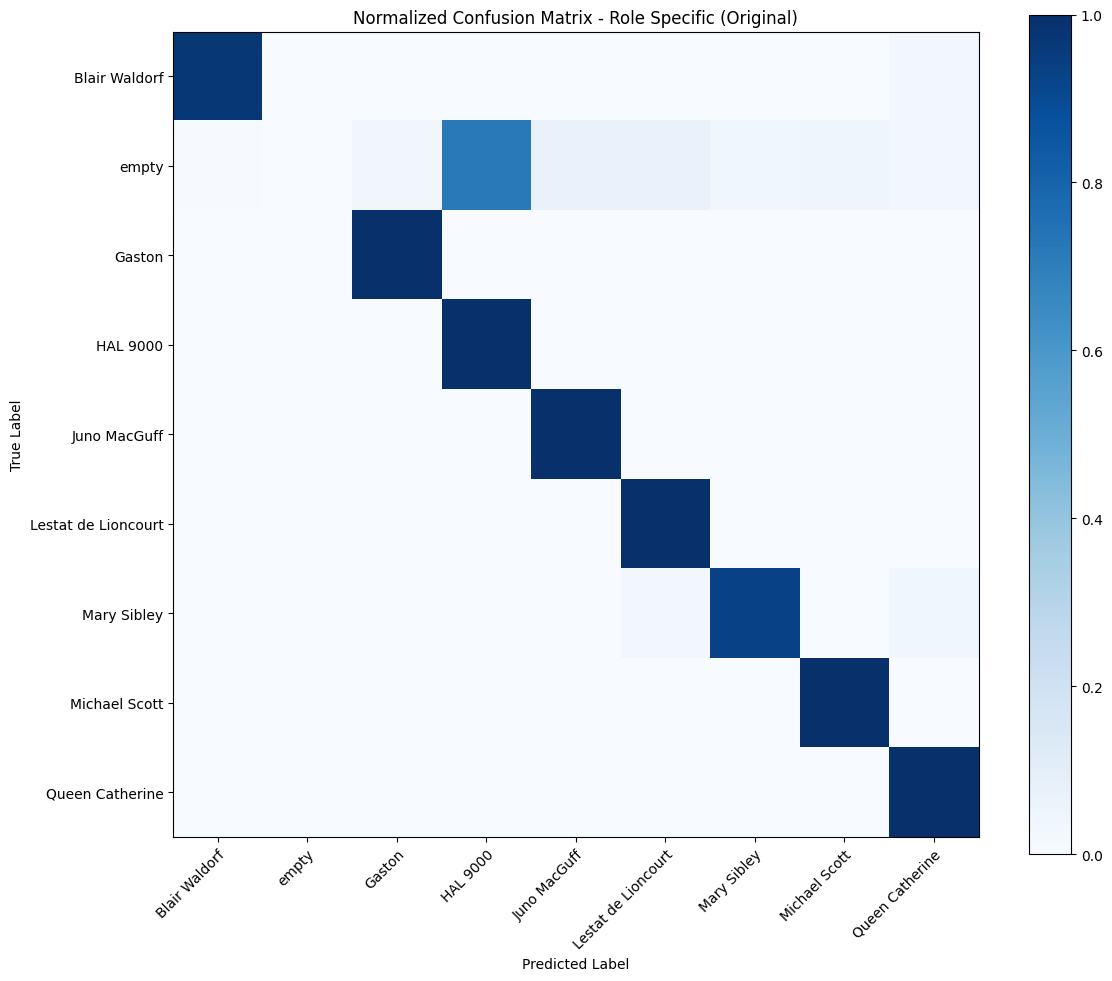

(              role                                               text  \
 0      Mary Sibley  ( the candlelight flickers , casting long shad...   
 1      Mary Sibley  ( the candlelight flickers , casting long , da...   
 2      Mary Sibley  ( a long silence descends . the candlelight fl...   
 3      Mary Sibley  ( a coldness settles over me , a darkness that...   
 4      Mary Sibley  ( a chilling stillness descends . my gaze beco...   
 ...            ...                                                ...   
 30775  Mary Sibley  ( a long , slow exhale . the question cuts to ...   
 30776  Mary Sibley  ( the air in the room seems to grow colder . m...   
 30777  Mary Sibley  ( the air around me seems to grow colder . my ...   
 30778  Mary Sibley  ( a shadow crosses my face . a tightening of t...   
 30779  Mary Sibley  ( a slow , assessing gaze . a question that re...   
 
                   pred    role_norm        pred_norm  correct  
 0          Mary Sibley  mary sibley      mar

In [5]:
name = "Role Specific (Original)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_role_specific.csv"

process_dataset(name, path)


Processing: Role Specific (0)


Inferencing Role Specific (0):   0%|          | 0/3078 [00:00<?, ?it/s]


Overall Accuracy: 41.75%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,272,272,79,0,0.774929,1.000000,0.873194
1,HAL 9000,197,183,255,14,0.417808,0.928934,0.576378
2,Michael Scott,153,137,70,16,0.661836,0.895425,0.761111
3,Queen Catherine,156,135,66,21,0.671642,0.865385,0.756303
4,Juno MacGuff,262,207,133,55,0.608824,0.790076,0.687708
5,Mary Sibley,178,139,74,39,0.652582,0.780899,0.710997
6,Lestat de Lioncourt,192,128,111,64,0.535565,0.666667,0.593968
7,Blair Waldorf,129,84,29,45,0.743363,0.651163,0.694215



Generating Confusion Matrix for Role Specific (0)...


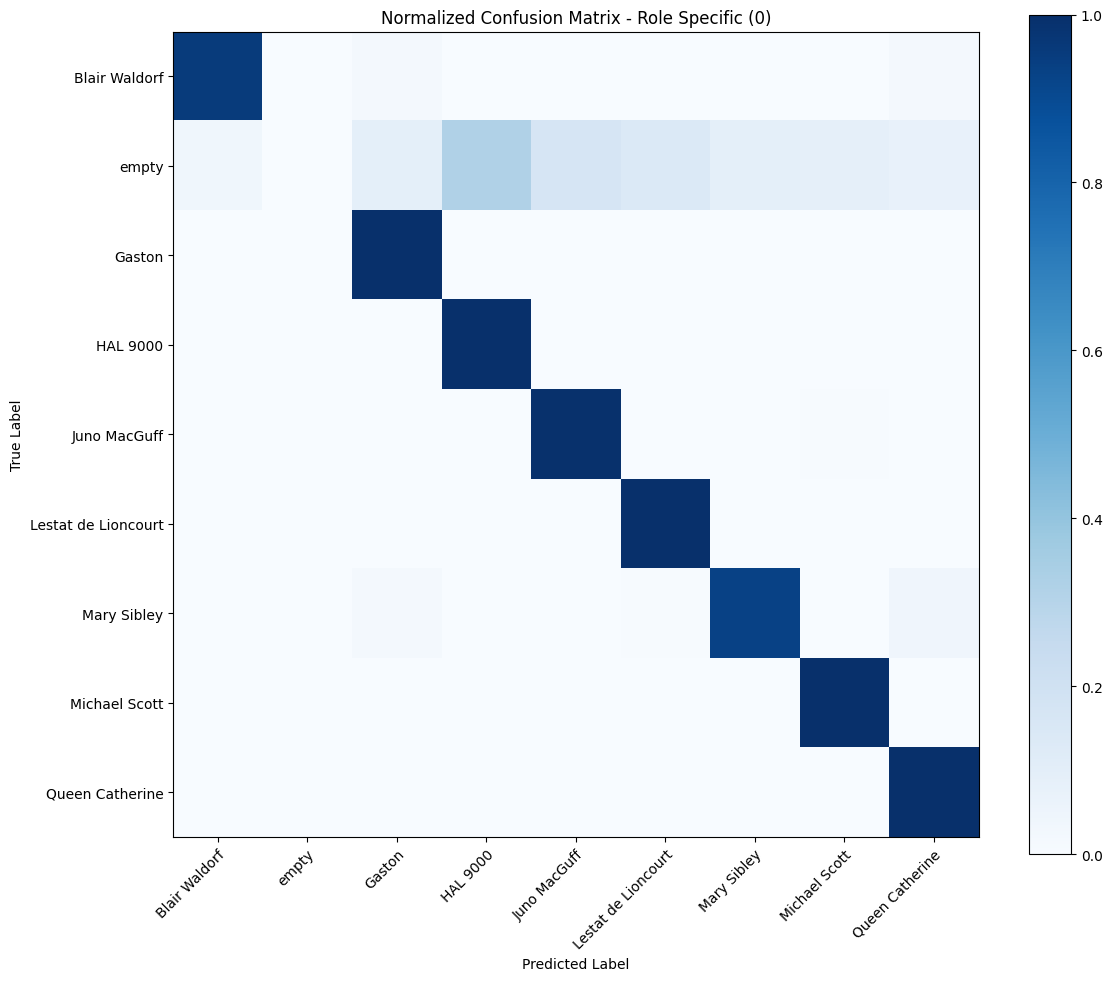

(                 role                                               text  \
 0         Mary Sibley  ( a slow exhale , the scent of woodsmoke and s...   
 1         Mary Sibley  ( a slow exhale , the scent of woodsmoke and s...   
 2         Mary Sibley  ( a slow exhale , the scent of woodsmoke and s...   
 3         Mary Sibley  ( a slow exhale , the scent of woodsmoke and s...   
 4         Mary Sibley  fear ? a curious question . it implies a weakn...   
 ...               ...                                                ...   
 3073  Queen Catherine  ( a slight , cool smile touches my lips as i s...   
 3074  Queen Catherine  ( a long , measured silence descends , my gaze...   
 3075  Queen Catherine  a most astute question . many rulers have grac...   
 3076  Queen Catherine  ( i adjust the heavy velvet of my gown , a sub...   
 3077  Queen Catherine  ( a slight , cool smile touches my lips as i s...   
 
                    pred        role_norm          pred_norm  correct  
 0

In [6]:
name = "Role Specific (0)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_role_specific_0.csv"

process_dataset(name, path)


Processing: Role Specific (102)


Inferencing Role Specific (102):   0%|          | 0/3078 [00:00<?, ?it/s]


Overall Accuracy: 41.39%

Top 8 Roles by Recall:


,label,support,tp,fp,fn,precision,recall,f1
0,Gaston,272,263,16,9,0.942652,0.966912,0.954628
1,HAL 9000,197,185,631,12,0.226716,0.939086,0.365252
2,Michael Scott,153,136,35,17,0.795322,0.888889,0.839506
3,Lestat de Lioncourt,192,164,50,28,0.766355,0.854167,0.807882
4,Queen Catherine,156,131,34,25,0.793939,0.839744,0.816199
5,Juno MacGuff,262,214,47,48,0.819923,0.816794,0.818356
6,Mary Sibley,178,122,20,56,0.859155,0.685393,0.762500
7,Blair Waldorf,129,59,4,70,0.936508,0.457364,0.614583



Generating Confusion Matrix for Role Specific (102)...


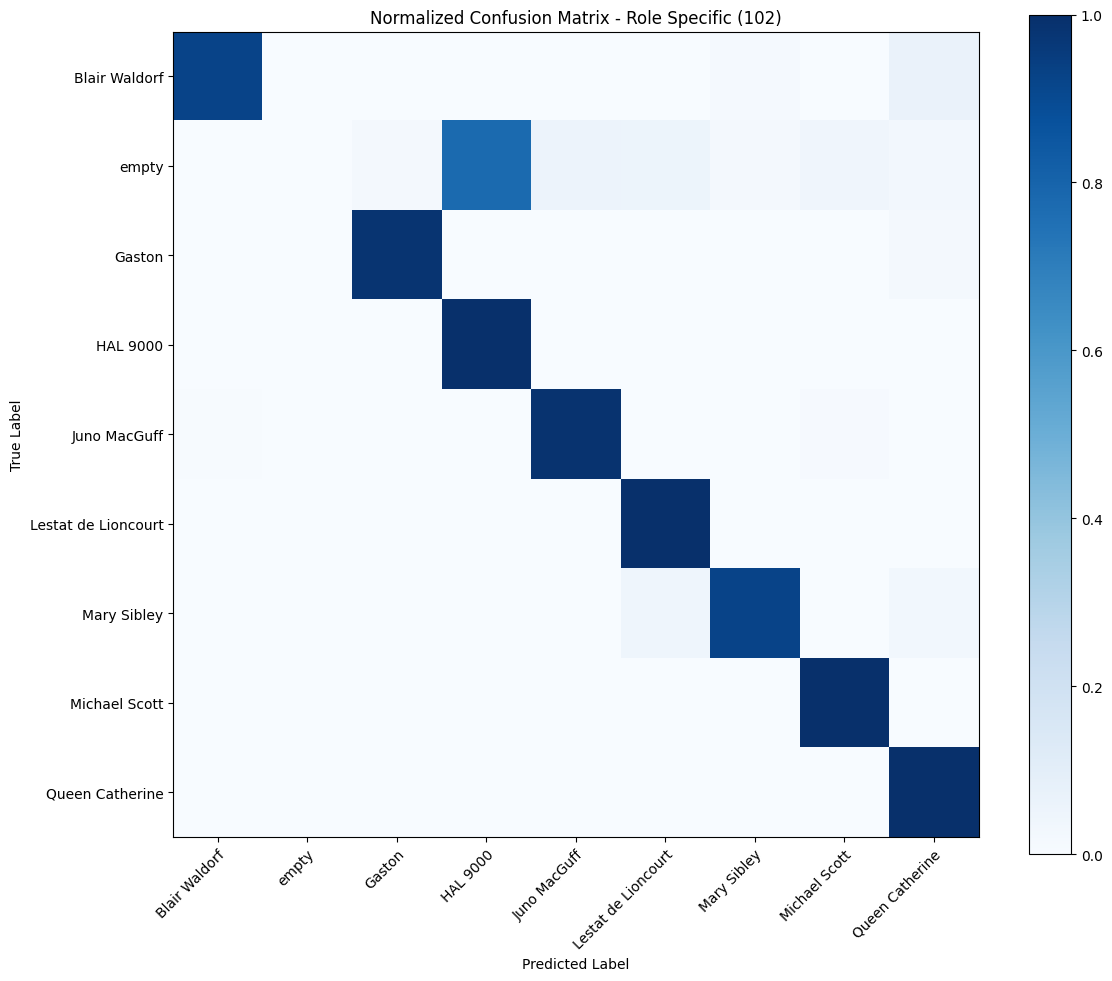

(               role                                               text  \
 0      Juno MacGuff  okay , here we go . this is … the big one . th...   
 1      Juno MacGuff  ugh , okay , deep thoughts again . love and re...   
 2      Juno MacGuff  oh , that 's a good question . it 's kinda my ...   
 3      Juno MacGuff  okay , wow . that 's … a big question . it 's ...   
 4      Juno MacGuff  okay , seriously . you 're digging deep now , ...   
 ...             ...                                                ...   
 3073  Blair Waldorf  ( a slight pause , as if considering whether t...   
 3074  Blair Waldorf  ( a slight pause , as if the question requires...   
 3075  Blair Waldorf  ( a slight pause , as if considering whether t...   
 3076  Blair Waldorf  ( a slight pause , as if considering whether t...   
 3077  Blair Waldorf  ( a slight pause , a subtle shift in tone . a ...   
 
                      pred      role_norm            pred_norm  correct  
 0            Juno MacGu

In [7]:
name = "Role Specific (102)"
path = "/kaggle/input/new-roles-datasets/Cleaned/instruction_role_specific_102.csv"

process_dataset(name, path)

Final Results Summary: {'Role Specific (Original)': 0.43187134502923974, 'Role Specific (0)': 0.4174788823911631, 'Role Specific (102)': 0.4139051332033788}


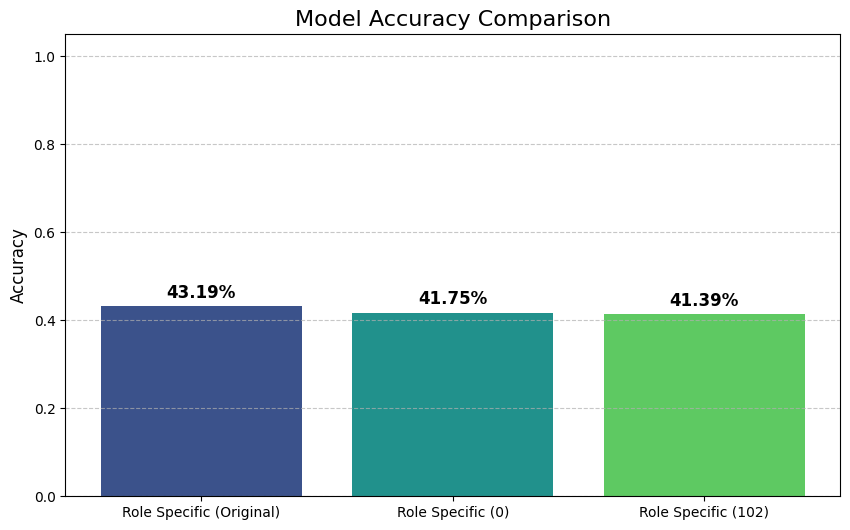

In [8]:
print("Final Results Summary:", GLOBAL_RESULTS)

if GLOBAL_RESULTS:
    plt.figure(figsize=(10, 6))
    
    names = list(GLOBAL_RESULTS.keys())
    values = list(GLOBAL_RESULTS.values())
    colors = sns.color_palette("viridis", len(names))
    
    bars = plt.bar(names, values, color=colors)
    
    plt.title("Model Accuracy Comparison", fontsize=16)
    plt.ylabel("Accuracy", fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                 f'{height:.2%}',
                 ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    plt.show()
else:
    print("No results found.")